# Neural proposal efficiency

We compare prior, data-informed, and neural birth proposals on held-out simulated two-planet radial-velocity scenes. This notebook calls the actual PCAT training-and-sampling benchmark. Its smoke settings check execution and artifact handling. These short chains do not establish convergence or an efficiency advantage.

In [1]:
import json
from contextlib import redirect_stdout
from io import StringIO
from uuid import uuid4

from pcat.demo import (
    display_example_visuals,
    load_example_namespace,
    run_example_script,
)

run_id = f"notebook_smoke_{uuid4().hex[:12]}"

## Smoke Run

Each proposal method uses two short chains on the same held-out simulated scene. The shared runner invokes the existing command-line pipeline with its smoke configuration. A fresh run ID preserves earlier checkpoints, chains, results, and figures.

In [2]:
with redirect_stdout(StringIO()):
    run_example_script(
        "neural_proposal_efficiency/neural_proposal_efficiency.py",
        "--smoke",
        "--run-id",
        run_id,
    )

## Recorded Smoke Outputs

We inspect the actual saved summary and efficiency figure from this run. Count-posterior disagreement, poor mixing, and Monte Carlo variation can dominate such short chains. No performance ranking is inferred from this smoke run.

In [3]:
with redirect_stdout(StringIO()):
    benchmark = load_example_namespace(
        "neural_proposal_efficiency/neural_proposal_efficiency.py"
    )
result_path = benchmark["RUNS_PATH"] / f"{run_id}_results.json"
print(f"Reading from {result_path.name}...")
with result_path.open(encoding="utf-8") as stream:
    summary = json.load(stream)["summary"]
summary

Reading from notebook_smoke_429174db3f92_results.json...


{'run_id': 'notebook_smoke_429174db3f92',
 'training_seed': 1053,
 'validation_seeds': [63],
 'chains_per_scene': 2,
 'training_scenes': 36,
 'training_elements': 85,
 'training_seconds': 1.4221534999960568,
 'sweeps_per_chain': 400,
 'uniform_fraction': 0.05,
 'paired_results': [{'validation_seed': 63,
   'neural_to_prior_ess_per_call_ratio': 5.905320480534722,
   'neural_to_data_informed_ess_per_call_ratio': 30.81180584287635,
   'neural_to_prior_ess_per_second_ratio': 3.5782730307821193,
   'neural_to_data_informed_ess_per_second_ratio': 18.252525346938352,
   'neural_to_prior_ess_per_end_to_end_second_ratio': 3.3686761333971065,
   'neural_to_data_informed_ess_per_end_to_end_second_ratio': 17.18338594666084,
   'neural_prior_count_posterior_total_variation': 0.45333333333333337,
   'neural_data_informed_count_posterior_total_variation': 0.8316666666666667,
   'prior_probability_two_planets': 0.25,
   'data_informed_probability_two_planets': 0.32,
   'neural_probability_two_planets'

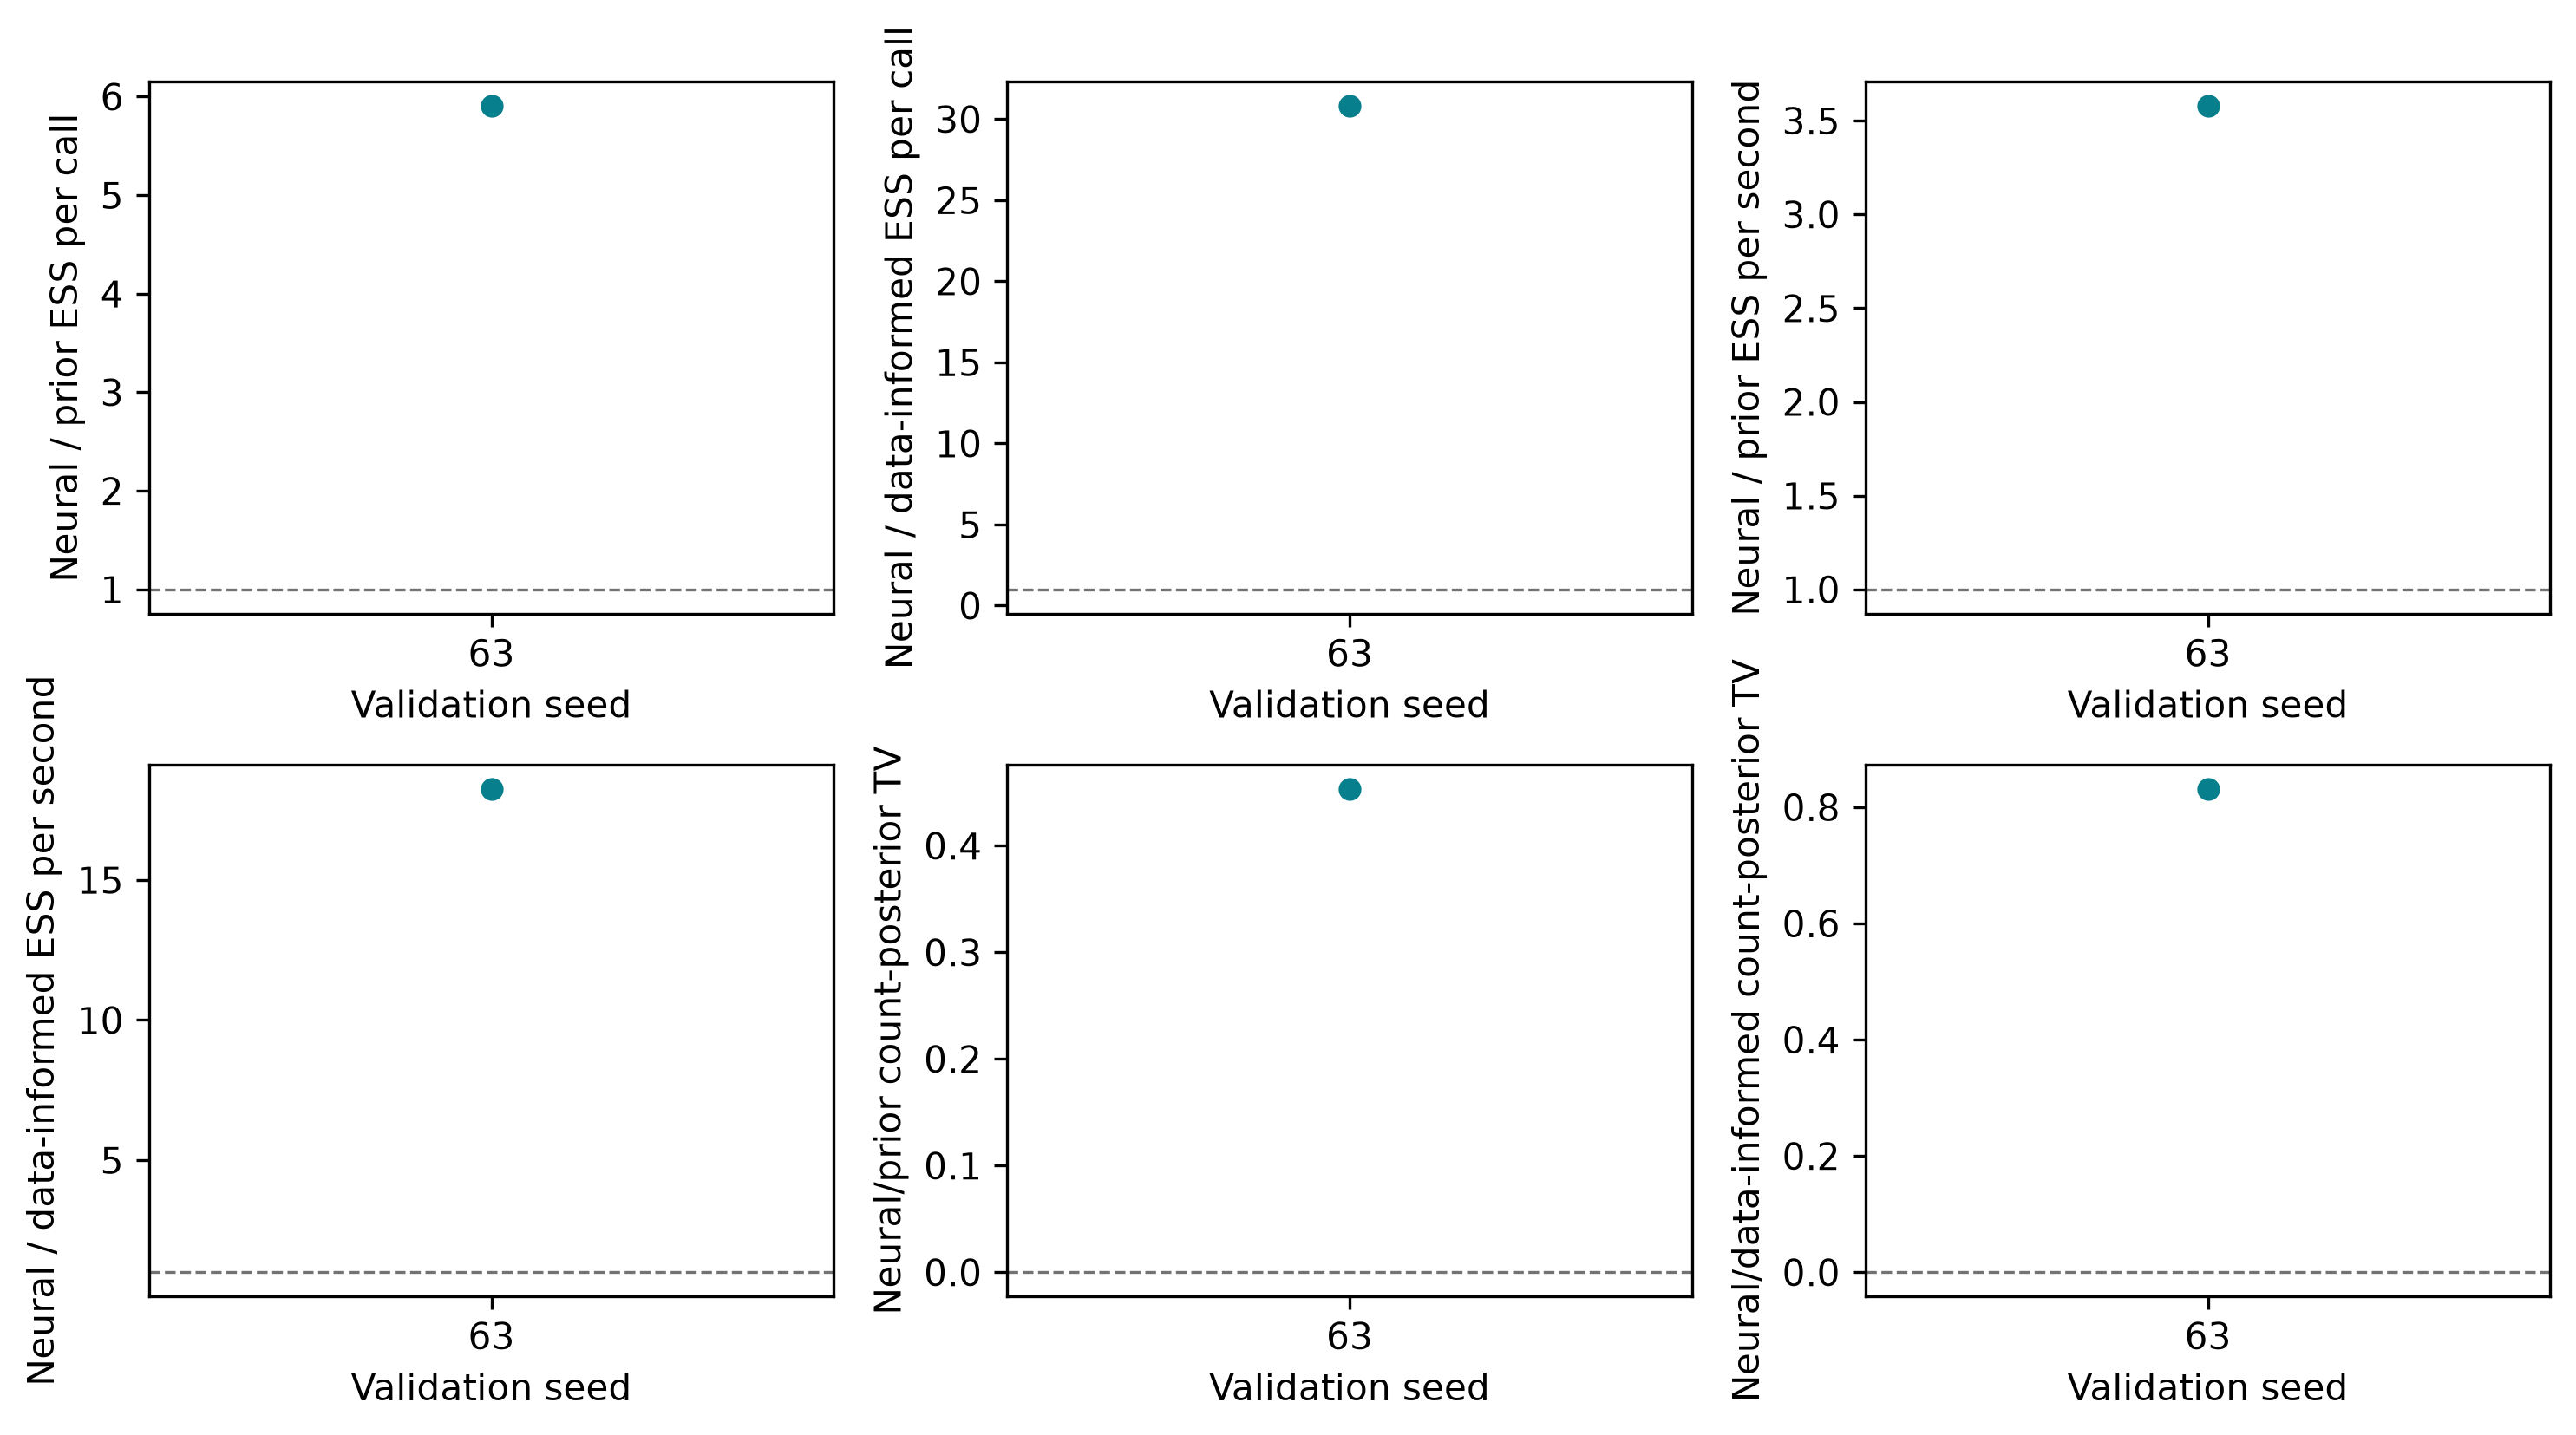

In [4]:
with redirect_stdout(StringIO()):
    display_example_visuals(
        "neural_proposal_efficiency",
        f"visuals/{run_id}_efficiency.png",
    )